<center><h1>Enriquez_Scott_HW5</h1></center>
<br>
<br>

Name: Scott Enriquez
<br>
GitHub Username: scottenriquez

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import math
%pip install -q matplotlib==3.11.2 numpy==2.5.4 'pandas[output-formatting]==3.1.0' scikit-learn==1.9.1 seaborn==0.13.2 scipy==1.18.1 statsmodels==0.15.0 xgboost==3.4.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LassoCV, LinearRegression, Ridge, RidgeCV
from sklearn.metrics import classification_report, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, GridSearchCV, KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from xgboost import XGBRegressor

### (a) Obtain Data

In [3]:
diagnosis_feature_columns = ['celsius_temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains',
                             'urethra_burning']
diagnosis_class_columns = ['inflammation_decision', 'nephritis_decision']
diagnosis_data = pd.read_csv('Homework-5-Data/diagnosis.data', sep='\t', encoding='utf-16', decimal=',', header=None,
                             names=diagnosis_feature_columns + diagnosis_class_columns)
for feature in diagnosis_feature_columns + diagnosis_class_columns:
    if feature != 'celsius_temperature':
        diagnosis_data[feature] = (diagnosis_data[feature] == 'yes').astype(int)

### (b) Build a decision tree

#### Evaluating Results Using a Test/Train Split

In [4]:
training_x_data, test_x_data, training_y_data, test_y_data = train_test_split(diagnosis_data[diagnosis_feature_columns],
                                                                              diagnosis_data[diagnosis_class_columns],
                                                                              test_size=0.2, random_state=9999)
decision_tree_classifier = DecisionTreeClassifier(random_state=9999)
decision_tree_classifier.fit(training_x_data, training_y_data)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",9999
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [5]:
predictions = decision_tree_classifier.predict(test_x_data)
prediction_results = pd.DataFrame(
    classification_report(test_y_data, predictions, target_names=['inflammation_decision', 'nephritis_decision'],
                          output_dict=True))
display(prediction_results)

/opt/homebrew/Cellar/jupyterlab/4.6.5/libexec/lib/python3.15/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/homebrew/Cellar/jupyterlab/4.6.5/libexec/lib/python3.15/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/homebrew/Cellar/jupyterlab/4.6.5/libexec/lib/python3.15/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_pr

,inflammation_decision,nephritis_decision,micro avg,macro avg,weighted avg,samples avg
precision,1.0,1.0,1.0,1.0,1.0,0.666667
recall,1.0,1.0,1.0,1.0,1.0,0.666667
f1-score,1.0,1.0,1.0,1.0,1.0,0.666667
support,11.0,9.0,20.0,20.0,20.0,20.000000


#### Building a Tree on the Entire Dataset

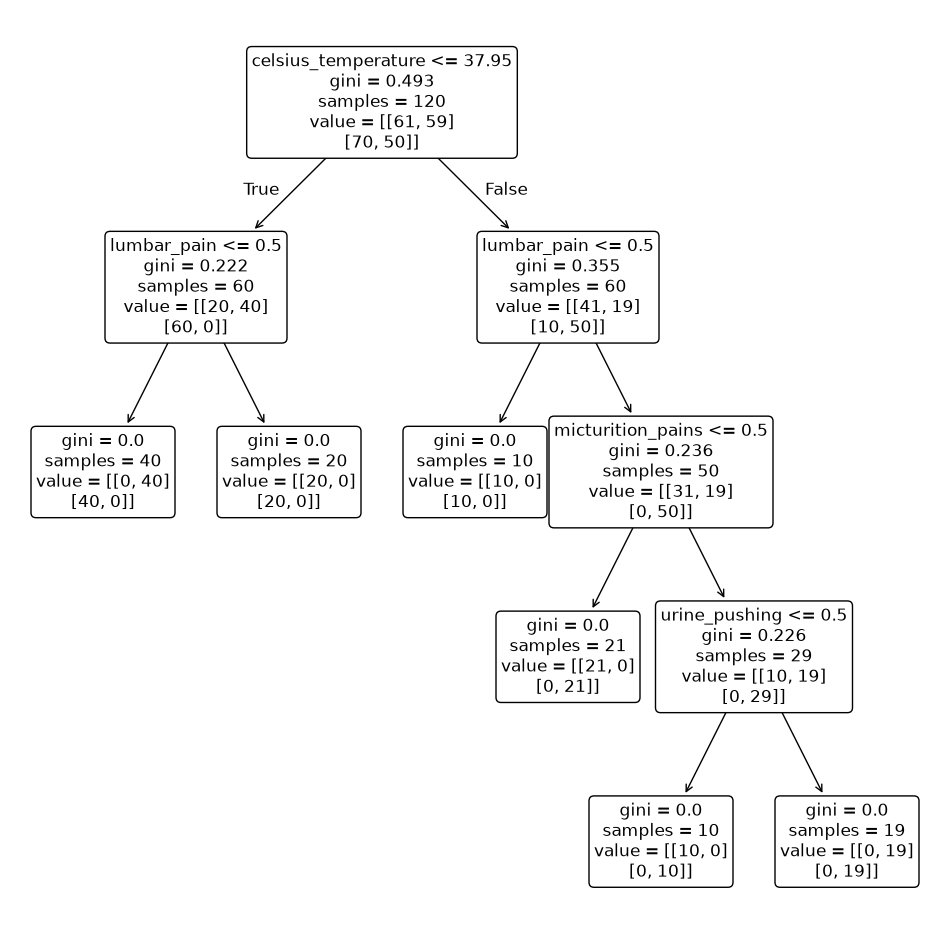

In [6]:
decision_tree_classifier_from_entire_dataset = DecisionTreeClassifier(random_state=9999)
decision_tree_classifier_from_entire_dataset.fit(diagnosis_data[diagnosis_feature_columns],
                                                 diagnosis_data[diagnosis_class_columns])
plt.figure(figsize=(12, 12))
plot_tree(
    decision_tree_classifier_from_entire_dataset,
    feature_names=diagnosis_feature_columns,
    rounded=True,
    fontsize=12,
)
plt.show()

For categorical features like `lumbar_pain` that have been converted from strings (i.e., `no`/`yes`) to integers (i.e., `0`/`1`), the `<= 0.5` decision split aligns with the `no`/`yes` split. The `value` attribute is a two-dimensional array (or list of lists). The first list contains two integers representing the number of `no`/`yes` values for inflammation classifications at the given node. The second list contains two integers representing the number of `no`/`yes` values for nephritis classifications at the given node. `samples` refers to the quantity of data points at that node.

### (c) Convert the decision rules

In [7]:
# from https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html
def tree_to_code(tree, feature_names):
    """
		Outputs a decision tree model as a Python function

		Parameters:
		-----------
		tree: decision tree model
			The decision tree to represent as a function
		feature_names: list
			The feature names of the dataset used for building the decision tree
		"""
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else 'undefined!'
        for i in tree_.feature
    ]
    print('def tree({}):'.format(', '.join(feature_names)))

    def recurse(node, depth):
        indent = '  ' * depth
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            print('{}if {} <= {}:'.format(indent, name, threshold))
            recurse(tree_.children_left[node], depth + 1)
            print('{}else:  # if {} > {}'.format(indent, name, threshold))
            recurse(tree_.children_right[node], depth + 1)
        else:
            print('{}return {}'.format(indent, tree_.value[node]))

    recurse(0, 1)

In [8]:
tree_to_code(decision_tree_classifier_from_entire_dataset, diagnosis_feature_columns)

def tree(celsius_temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, urethra_burning):
  if celsius_temperature <= 37.95000076293945:
    if lumbar_pain <= 0.5:
      return [[0. 1.]
 [1. 0.]]
    else:  # if lumbar_pain > 0.5
      return [[1. 0.]
 [1. 0.]]
  else:  # if celsius_temperature > 37.95000076293945
    if lumbar_pain <= 0.5:
      return [[1. 0.]
 [1. 0.]]
    else:  # if lumbar_pain > 0.5
      if micturition_pains <= 0.5:
        return [[1. 0.]
 [0. 1.]]
      else:  # if micturition_pains > 0.5
        if urine_pushing <= 0.5:
          return [[1. 0.]
 [0. 1.]]
        else:  # if urine_pushing > 0.5
          return [[0. 1.]
 [0. 1.]]


1. IF temperature ≤ 37.95000076293945 AND no lumbar pain THEN inflammation = yes, nephritis = no
2. IF temperature ≤ 37.95000076293945 AND lumbar pain THEN inflammation = no, nephritis = no
3. IF temperature > 37.95000076293945  AND no lumbar pain THEN inflammation = no, nephritis = no
4. IF temperature > 37.95000076293945 AND lumbar pain AND no micturition pains THEN inflammation = no, nephritis = yes
5. IF temperature > 37.95000076293945 AND lumbar pain AND micturition pains AND no urine pushing THEN inflammation = no, nephritis = yes
6. IF temperature > 37.95000076293945 AND lumbar pain AND micturition pains AND urine pushing THEN inflammation = yes, nephritis = yes

### (d) Cost Complexity Pruning

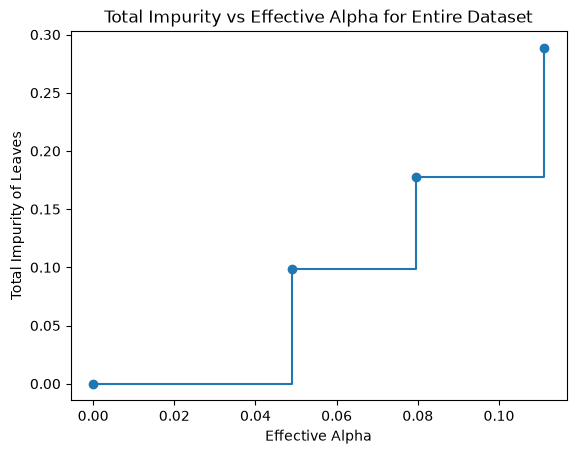

In [9]:
cost_complexity_pruning_path = decision_tree_classifier_from_entire_dataset.cost_complexity_pruning_path(
    diagnosis_data[diagnosis_feature_columns], diagnosis_data[diagnosis_class_columns])
figure, axis = plt.subplots()
axis.plot(cost_complexity_pruning_path.ccp_alphas[:-1], cost_complexity_pruning_path.impurities[:-1], marker='o',
          drawstyle='steps-post')
axis.set_xlabel('Effective Alpha')
axis.set_ylabel('Total Impurity of Leaves')
axis.set_title('Total Impurity vs Effective Alpha for Entire Dataset')
plt.show()

In [10]:
k_fold = KFold(n_splits=5, shuffle=True, random_state=9999)
mean_accuracy_by_alpha = []
node_counts_by_alpha = []
for alpha in cost_complexity_pruning_path.ccp_alphas:
    decision_tree = DecisionTreeClassifier(random_state=9999, ccp_alpha=alpha)
    cross_validation_accuracies = cross_val_score(decision_tree, diagnosis_data[diagnosis_feature_columns],
                                                  diagnosis_data[diagnosis_class_columns], cv=k_fold)
    mean_accuracy_by_alpha.append(cross_validation_accuracies.mean())
    node_counts_by_alpha.append(decision_tree.fit(diagnosis_data[diagnosis_feature_columns],
                                                  diagnosis_data[diagnosis_class_columns]).tree_.node_count)
pruning_results = pd.DataFrame(
    {'cost_complexity_pruning_alpha': cost_complexity_pruning_path.ccp_alphas,
     'mean_cross_validation_accuracy': mean_accuracy_by_alpha, 'node_count': node_counts_by_alpha})
display(pruning_results)

,cost_complexity_pruning_alpha,mean_cross_validation_accuracy,node_count
0,0.000000,1.000000,11
1,0.049083,0.908333,7
2,0.079472,0.783333,5
3,0.111111,0.608333,3
4,0.204236,0.358333,1


The best cross validation accuracy for a non-zero alpha is 0.908333 and contains seven nodes. The best tree from a cross-validation accuracy perspective is the unpruned tree. Assuming that alpha cannot be zero, the minimal tree is shown below at the cost of 0.091667 cross-validation accuracy.

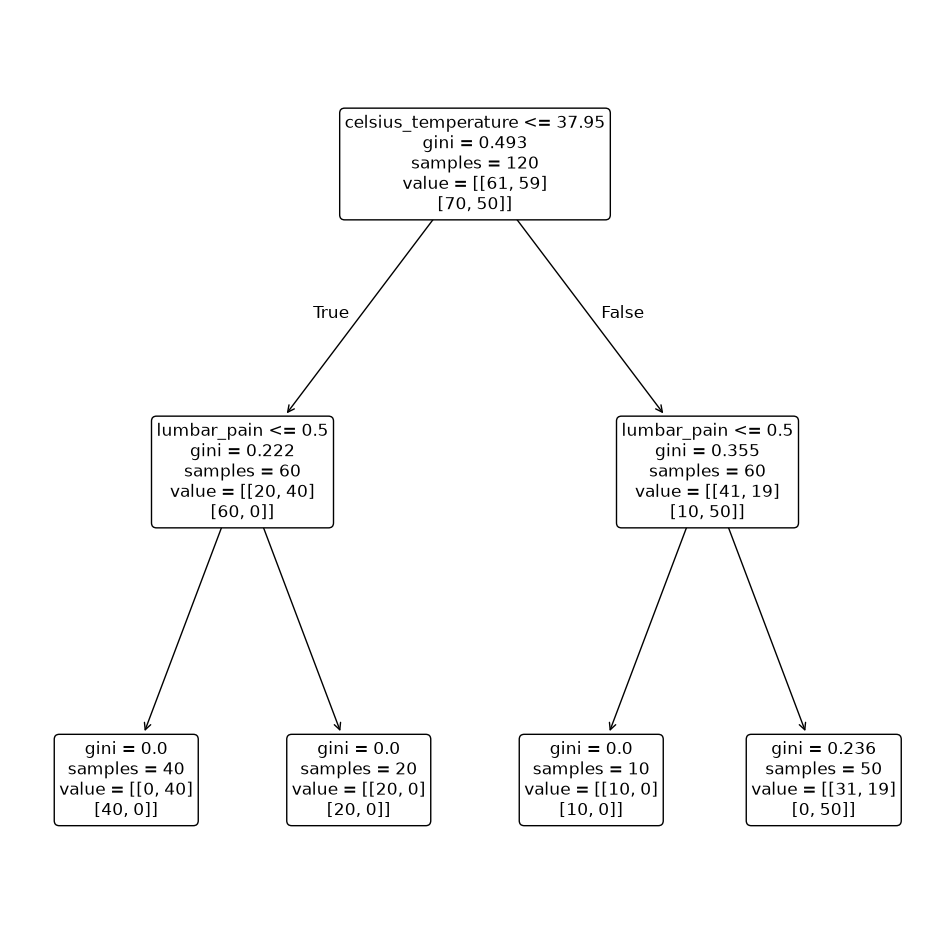

In [11]:
minimal_decision_tree = DecisionTreeClassifier(random_state=9999,
                                               ccp_alpha=pruning_results.iloc[1].cost_complexity_pruning_alpha)
minimal_decision_tree.fit(diagnosis_data[diagnosis_feature_columns],
                          diagnosis_data[diagnosis_class_columns])
plt.figure(figsize=(12, 12))
plot_tree(
    minimal_decision_tree,
    feature_names=diagnosis_feature_columns,
    rounded=True,
    fontsize=12,
)
plt.show()

In [12]:
tree_to_code(minimal_decision_tree, diagnosis_feature_columns)

def tree(celsius_temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, urethra_burning):
  if celsius_temperature <= 37.95000076293945:
    if lumbar_pain <= 0.5:
      return [[0. 1.]
 [1. 0.]]
    else:  # if lumbar_pain > 0.5
      return [[1. 0.]
 [1. 0.]]
  else:  # if celsius_temperature > 37.95000076293945
    if lumbar_pain <= 0.5:
      return [[1. 0.]
 [1. 0.]]
    else:  # if lumbar_pain > 0.5
      return [[0.62 0.38]
 [0.   1.  ]]


1. IF temperature ≤ 37.95000076293945 AND no lumbar pain THEN inflammation = yes, nephritis = no
2. IF temperature ≤ 37.95000076293945 AND lumbar pain THEN inflammation = no, nephritis = no
3. IF temperature > 37.95000076293945 AND no lumbar pain THEN inflammation = no, nephritis = no
4. IF temperature > 37.95000076293945 AND lumbar pain THEN inflammation = no, nephritis = yes

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [13]:
community_data_columns = [line.split()[1] for line in open('Homework-5-Data/communities.names')
                          if line.startswith('@attribute')]
community_data = pd.read_csv('Homework-5-Data/communities.data', header=None, names=community_data_columns,
                             na_values='?')
del community_data['state']
del community_data['county']
del community_data['community']
del community_data['communityname']
del community_data['fold']
community_target_column = 'ViolentCrimesPerPop'
community_feature_columns = community_data.columns.drop(community_target_column)
training_row_count = 1495
training_x_data = community_data.drop(columns=community_target_column).iloc[0:training_row_count]
training_y_data = community_data[community_target_column].iloc[0:training_row_count]
test_x_data = community_data.drop(columns=community_target_column).iloc[training_row_count:]
test_y_data = community_data[community_target_column].iloc[training_row_count:]

### (b) Missing values

In [14]:
simple_imputer = SimpleImputer(missing_values=np.nan, strategy='mean').set_output(transform='pandas')
training_x_data_imputed = simple_imputer.fit_transform(training_x_data)

### (c) Plot a correlation matrix

In [15]:
correlation_matrix = pd.concat([training_x_data_imputed, training_y_data], axis=1).corr()

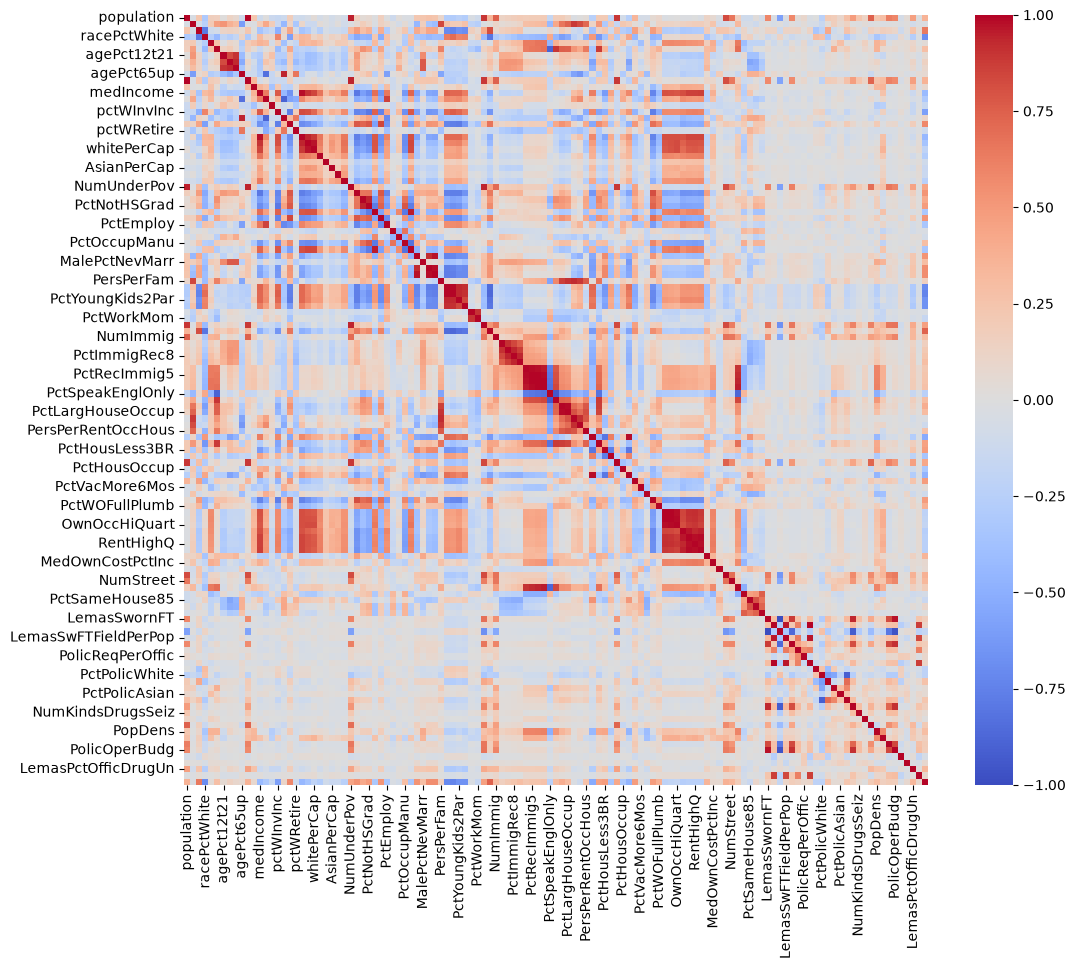

In [16]:
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1, center=0)
plt.show()

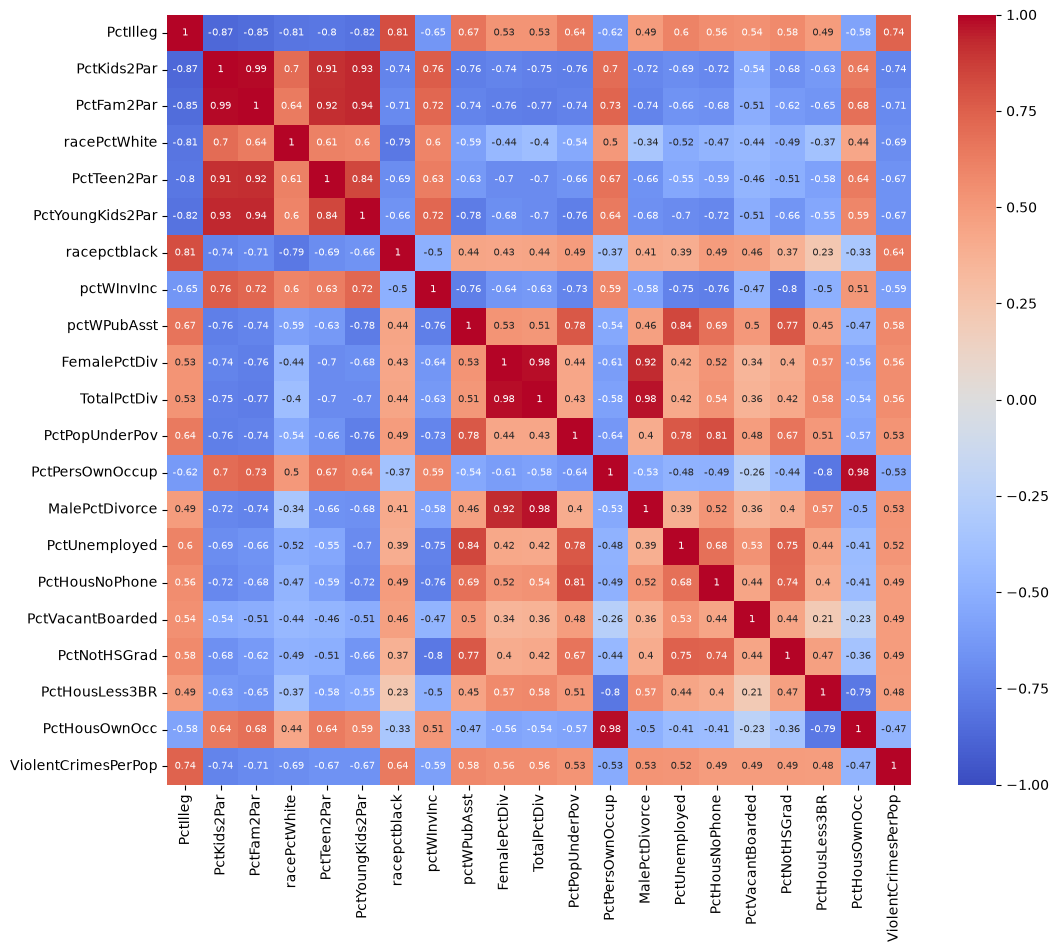

In [17]:
top_features_by_correlation = correlation_matrix['ViolentCrimesPerPop'].drop('ViolentCrimesPerPop').abs().nlargest(
    20).index.tolist()
top_features_by_correlation.append('ViolentCrimesPerPop')
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix.loc[top_features_by_correlation, top_features_by_correlation], cmap='coolwarm', vmin=-1,
            vmax=1, center=0, annot=True, annot_kws={'size': 7})
plt.show()

The complete correlation matrix is above. Given the number of features (123 by 123), I created a second matrix based on the top 20 features by correlation with the target of `ViolentCrimesPerPop`. The bottom row shows the most correlated features to the target.

### (d) Calculate the Coefficient of Variation CV

In [18]:
coefficient_of_variation = (training_x_data_imputed.std() / training_x_data_imputed.mean()).sort_values(ascending=False)
print(coefficient_of_variation)

NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
                         ...   
NumKindsDrugsSeiz      0.144382
RacialMatchCommPol     0.134853
PctPolicWhite          0.122813
LemasPctPolicOnPatr    0.115739
LemasSwFTFieldOps      0.064288
Length: 122, dtype: float64


### (e) Scatter plots and box plots for highest CV features

In [19]:
top_features_by_coefficient_of_variation = coefficient_of_variation.iloc[:math.floor(math.sqrt(128))].index.tolist()
display(top_features_by_coefficient_of_variation)

['NumStreet',
 'NumInShelters',
 'NumIlleg',
 'NumImmig',
 'LemasPctOfficDrugUn',
 'NumUnderPov',
 'population',
 'numbUrban',
 'HousVacant',
 'LandArea',
 'racePctHisp']

In [20]:
highest_coefficient_of_variation_training_x_data = training_x_data_imputed[top_features_by_coefficient_of_variation]

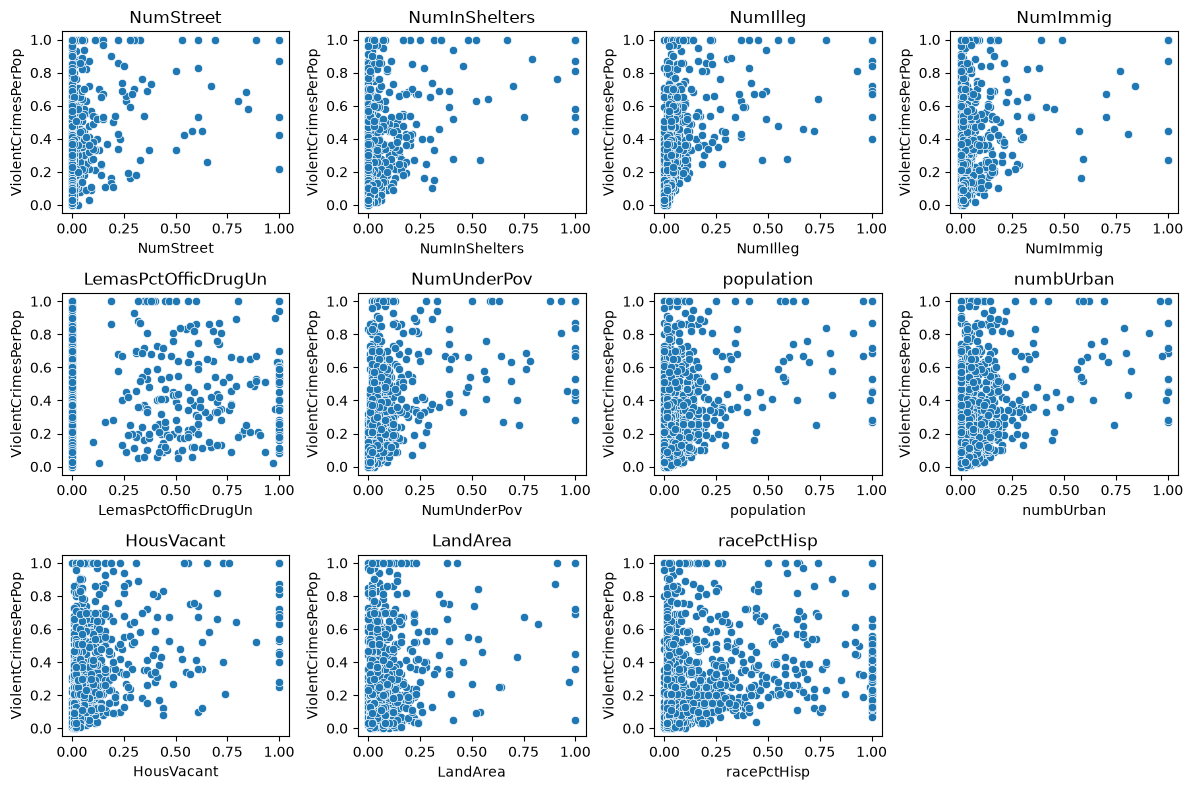

In [21]:
figure, axes = plt.subplots(3, 4, figsize=(12, 8))
for axis, feature in zip(axes.flat, top_features_by_coefficient_of_variation):
    sns.scatterplot(x=highest_coefficient_of_variation_training_x_data[feature], y=training_y_data, ax=axis)
    axis.set_title(feature)
for axis in axes.flat[len(top_features_by_coefficient_of_variation):]:
    axis.set_visible(False)
plt.tight_layout()
plt.show()

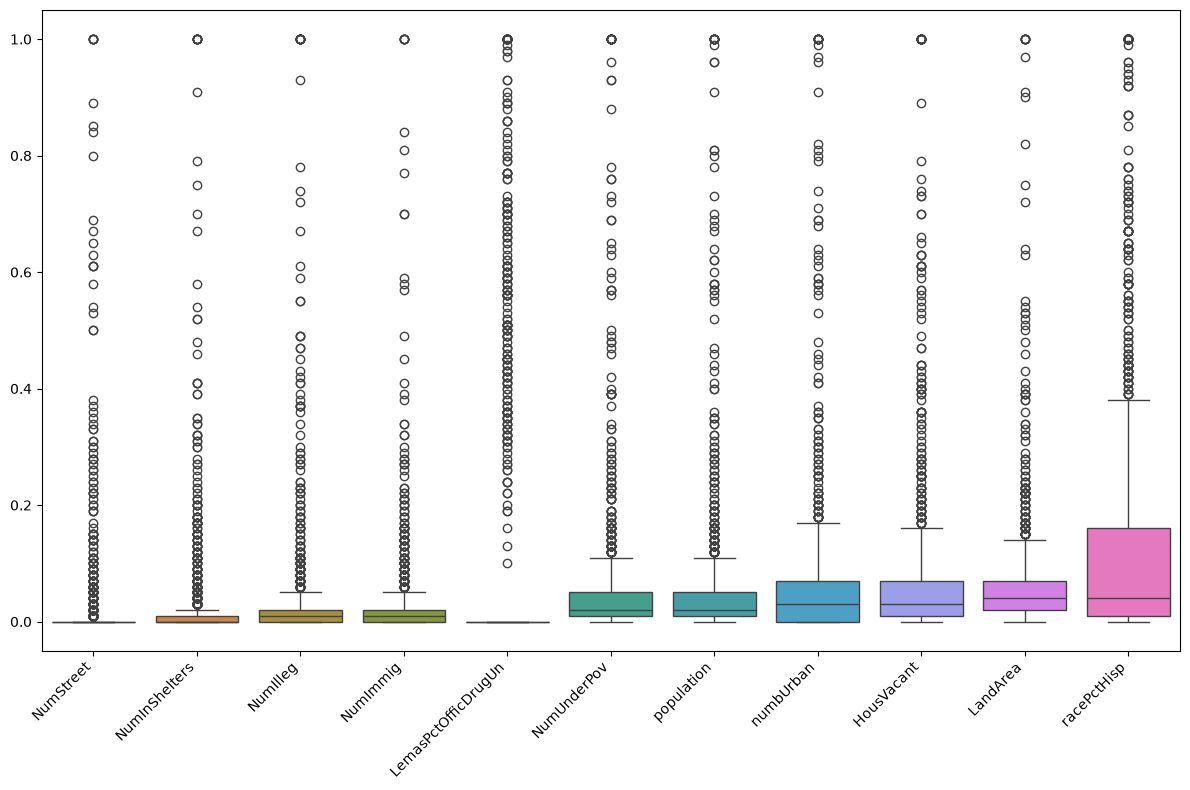

In [22]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=highest_coefficient_of_variation_training_x_data)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Plots alone aren't enough to draw conclusions about the significance of these features.

### (f) Fit a linear model

In [23]:
linear_regression = LinearRegression(fit_intercept=True)
linear_regression.fit(training_x_data_imputed, training_y_data)
predictions = linear_regression.predict(simple_imputer.transform(test_x_data))
print(f'OLS Linear Regression MSE: {mean_squared_error(test_y_data, predictions)}')
print(f'OLS Linear Regression R^2: {r2_score(test_y_data, predictions)}')

OLS Linear Regression MSE: 0.0181419711355301
OLS Linear Regression R^2: 0.6185079073449944


### (g) Fit a ridge regression model

In [24]:
ridge_alpha_space = np.logspace(-4, 4, 100)
ridge_cross_validation = RidgeCV(alphas=ridge_alpha_space)
ridge_cross_validation.fit(training_x_data_imputed, training_y_data)
best_ridge_alpha_no_scaling = ridge_cross_validation.alpha_
print(f'Best ridge alpha (no scaling): {best_ridge_alpha_no_scaling}')

Best ridge alpha (no scaling): 2.310129700083163


In [25]:
ridge_regression = Ridge(alpha=best_ridge_alpha_no_scaling)
ridge_regression.fit(training_x_data_imputed, training_y_data)
predictions = ridge_regression.predict(simple_imputer.transform(test_x_data))
print(f'Ridge MSE: {mean_squared_error(test_y_data, predictions)}')
print(f'Ridge R^2: {r2_score(test_y_data, predictions)}')

Ridge MSE: 0.017599613792452538
Ridge R^2: 0.6299126789782297


In [26]:
ridge_cross_validation_pipeline = make_pipeline(StandardScaler(), RidgeCV(alphas=ridge_alpha_space))
ridge_cross_validation_pipeline.fit(training_x_data_imputed, training_y_data)
best_ridge_alpha_with_scaling = ridge_cross_validation_pipeline.named_steps['ridgecv'].alpha_
print(f'Best ridge alpha (with scaling): {best_ridge_alpha_with_scaling}')

Best ridge alpha (with scaling): 79.24828983539186


In [27]:
ridge_regression_with_scaling = make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha_with_scaling))
ridge_regression_with_scaling.fit(training_x_data_imputed, training_y_data)
predictions = ridge_regression_with_scaling.predict(simple_imputer.transform(test_x_data))
print(f'Ridge (Scaled) MSE: {mean_squared_error(test_y_data, predictions)}')
print(f'Ridge (Scaled) R^2: {r2_score(test_y_data, predictions)}')

Ridge (Scaled) MSE: 0.01754100978503473
Ridge (Scaled) R^2: 0.6311450128443112


### (h) Fit a LASSO model

In [28]:
lasso_cross_validation = LassoCV()
lasso_cross_validation.fit(training_x_data_imputed, training_y_data)
best_lasso_alpha_no_scaling = lasso_cross_validation.alpha_
print(f'Best Lasso alpha (no scaling): {best_lasso_alpha_no_scaling}')

Best Lasso alpha (no scaling): 0.0001161472362682987


/opt/homebrew/Cellar/jupyterlab/4.6.5/libexec/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.752930e-03, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(
/opt/homebrew/Cellar/jupyterlab/4.6.5/libexec/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.011361e-02, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(


In [29]:
lasso_regression = Lasso(alpha=best_lasso_alpha_no_scaling)
lasso_regression.fit(training_x_data_imputed, training_y_data)
predictions = lasso_regression.predict(simple_imputer.transform(test_x_data))
lasso_coefficients = pd.Series(lasso_regression.coef_, index=training_x_data_imputed.columns)
print(f'Lasso MSE: {mean_squared_error(test_y_data, predictions)}')
print(f'Lasso R^2: {r2_score(test_y_data, predictions)}')
print('Selected Lasso Features:')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print(lasso_coefficients[lasso_coefficients != 0])

Lasso MSE: 0.01775820921631968
Lasso R^2: 0.6265777105955443
Selected Lasso Features:
racepctblack             0.271984
racePctAsian            -0.015671
agePct12t21              0.066658
agePct12t29             -0.265373
pctUrban                 0.040512
pctWWage                -0.084811
pctWFarmSelf             0.026607
pctWInvInc              -0.098512
pctWSocSec               0.048560
pctWPubAsst              0.038868
pctWRetire              -0.108431
whitePerCap             -0.058019
blackPerCap             -0.021056
indianPerCap            -0.031131
AsianPerCap              0.029002
OtherPerCap              0.022693
HispPerCap               0.023950
PctPopUnderPov          -0.141188
PctLess9thGrade         -0.018354
PctEmploy                0.137394
PctEmplManu             -0.015673
PctOccupManu             0.010102
MalePctDivorce           0.118069
MalePctNevMarr           0.133172
FemalePctDiv            -0.078612
PctKids2Par             -0.196600
PctYoungKids2Par        -0.037

In [30]:
lasso_cross_validation_pipeline = make_pipeline(StandardScaler(), LassoCV())
lasso_cross_validation_pipeline.fit(training_x_data_imputed, training_y_data)
best_lasso_alpha_with_scaling = lasso_cross_validation_pipeline.named_steps['lassocv'].alpha_
print(f'Best Lasso alpha (with scaling): {best_lasso_alpha_with_scaling}')

Best Lasso alpha (with scaling): 0.0007630833878262516


/opt/homebrew/Cellar/jupyterlab/4.6.5/libexec/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.826702e-03, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(
/opt/homebrew/Cellar/jupyterlab/4.6.5/libexec/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.021131e-02, tolerance: 6.746e-03
  model = cd_fast.enet_coordinate_descent_gram(
/opt/homebrew/Cellar/jupyterlab/4.6.5/libexec/lib/python3.15/site-packages/sklearn/linear_model/_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of ite

In [31]:
lasso_regression_with_scaling = make_pipeline(StandardScaler(), Lasso(alpha=best_lasso_alpha_with_scaling))
lasso_regression_with_scaling.fit(training_x_data_imputed, training_y_data)
predictions = lasso_regression_with_scaling.predict(simple_imputer.transform(test_x_data))
lasso_coefficients_with_scaling = pd.Series(lasso_regression_with_scaling[-1].coef_,
                                            index=training_x_data_imputed.columns)
print(f'Lasso (Scaled) MSE: {mean_squared_error(test_y_data, predictions)}')
print(f'Lasso (Scaled) R^2: {r2_score(test_y_data, predictions)}')
print('Selected Lasso Features:')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
   print(lasso_coefficients_with_scaling[lasso_coefficients_with_scaling != 0])

Lasso (Scaled) MSE: 0.017805339276862262
Lasso (Scaled) R^2: 0.6255866526069152
Selected Lasso Features:
racepctblack             0.068248
racePctAsian            -0.000907
agePct12t21              0.010367
agePct12t29             -0.038253
pctUrban                 0.016588
pctWWage                -0.012059
pctWFarmSelf             0.004100
pctWInvInc              -0.020836
pctWSocSec               0.008884
pctWPubAsst              0.006135
pctWRetire              -0.017181
whitePerCap             -0.008624
blackPerCap             -0.003639
indianPerCap            -0.005237
AsianPerCap              0.005306
OtherPerCap              0.003816
HispPerCap               0.003992
PctPopUnderPov          -0.026742
PctLess9thGrade         -0.002048
PctEmploy                0.021190
PctEmplManu             -0.001042
MalePctDivorce           0.018976
MalePctNevMarr           0.020714
FemalePctDiv            -0.010066
PctKids2Par             -0.039806
PctYoungKids2Par        -0.008176
PctTeen2Par

Unscaled Lasso selected 75 features. Scaled Lasso selected 73 features. 69 of those features are the same. The MSEs are close as well, showing that there's not much difference between the two.

### (i) Fit a PCR model

In [32]:
feature_count = len(community_feature_columns)
component_cross_validation_pipeline = make_pipeline(StandardScaler(), PCA(), LinearRegression())
component_cross_validation = (
    GridSearchCV(component_cross_validation_pipeline,
                 param_grid={'pca__n_components': range(1, feature_count + 1)},
                 cv=KFold(n_splits=5, shuffle=True, random_state=9999)))
component_cross_validation.fit(training_x_data_imputed, training_y_data)
best_component_count = component_cross_validation.best_params_['pca__n_components']
print(f'Best component count: {best_component_count}')

Best component count: 95


In [33]:
principal_component_regression_pipeline = (
    make_pipeline(StandardScaler(), PCA(n_components=best_component_count), LinearRegression()))
principal_component_regression_pipeline.fit(training_x_data_imputed, training_y_data)
predictions = principal_component_regression_pipeline.predict(simple_imputer.transform(test_x_data))
print(f'PCR (Scaled) MSE: {mean_squared_error(test_y_data, predictions)}')
print(f'PCR (Scaled) R^2: {r2_score(test_y_data, predictions)}')

PCR (Scaled) MSE: 0.01839293123038782
PCR (Scaled) R^2: 0.6132306807941996


### (j) Fit a boosting tree

In [34]:
xgboost_cross_validation = GridSearchCV(XGBRegressor(random_state=9999),
                                        param_grid={'reg_alpha': list(np.logspace(-4, 4, 100))},
                                        cv=KFold(n_splits=5, shuffle=True, random_state=9999))
xgboost_cross_validation.fit(training_x_data_imputed, training_y_data)
best_xgboost_alpha = xgboost_cross_validation.best_params_['reg_alpha']
print(f'Best XGBoost alpha: {best_xgboost_alpha}')

Best XGBoost alpha: 3.351602650938848


In [35]:
xgboost_regressor = XGBRegressor(alpha=best_xgboost_alpha)
xgboost_regressor.fit(training_x_data_imputed, training_y_data)
predictions = xgboost_regressor.predict(simple_imputer.transform(test_x_data))
print(f'XGBoost MSE: {mean_squared_error(test_y_data, predictions)}')
print(f'XGBoost R^2: {r2_score(test_y_data, predictions)}')

XGBoost MSE: 0.017701683925082447
XGBoost R^2: 0.6277663329057074
